# V3 / 02C — Fast M2-only historical seven-circle validation (Nadine 34)

Train **M2 only**: partial tree crowns + 27 exhaustive Nadine development circles, with conflicting pixels assigned zero loss weight. Preserve the same original seven holdout IDs, TinyUNet architecture, 25 epochs, and inference over complete held-out circles. Enable optional CUDA mixed precision for speed. **M1 and M3 are intentionally skipped.**


## 01 — Inputs and frozen design


In [2]:
%pip -q install rasterio geopandas pyogrio shapely pandas matplotlib scikit-learn
from pathlib import Path
import json, warnings, math, random, time
import numpy as np, pandas as pd, geopandas as gpd, rasterio, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from rasterio.windows import Window
from rasterio.features import rasterize
from shapely.geometry import box
from shapely.ops import unary_union
from shapely import make_valid
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import average_precision_score, roc_auc_score
from IPython.display import display
from google.colab import drive
if not Path('/content/drive/MyDrive').exists():drive.mount('/content/drive')
ROOT=next((p for p in [Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final'),
                         Path('/content/drive/MyDrive/Musanga/Final')] if p.is_dir()),None)
assert ROOT is not None
OUT=ROOT/'Outputs/V3/02C_nadine34_legacy7';OUT.mkdir(parents=True,exist_ok=True)
REF=ROOT/'Outputs/V3/01_reference_data_nadine34'
A=json.loads((ROOT/'Outputs/V3/00_input_audit/00_input_manifest.json').read_text())
assert A.get('schema_version')=='v3_input_audit_5_nadine_circles'
assert A['exhaustive_annotations'].get('all_annotation_polygons_musanga') is True
assert int(A['exhaustive_annotations']['verified_exhaustive_circle_count'])==34
mosaics={m['file']:m for m in A['mosaics']}
splits=pd.read_csv(REF/'01_cv_window_manifest.csv')
links=pd.read_csv(REF/'01_circle_spatial_folds.csv')
repairs=pd.read_csv(REF/'01_geometry_repairs.csv')
assert links.circle_id.nunique()==34
assert links.groupby('site').circle_id.nunique().to_dict()=={'Baego':7,'MOS':15,'Yangambi':7,'Yoko':5}
assert links.circle_id.is_unique
FOLD=0;SEED=20261016;CROP=256;EPOCHS=25;BATCH=8
MAX_PARTIAL_PER_MOSAIC=250
MAX_EXHAUSTIVE_PER_SITE=260
HOLDOUT_COUNTS={'Baego':1,'MOS':2,'Yangambi':2,'Yoko':2}
assert torch.cuda.is_available(),'Select Runtime > Change runtime type > GPU for the pilot.'
device='cuda';torch.manual_seed(SEED);np.random.seed(SEED);random.seed(SEED)
print('NADINE 34 circles; legacy seven-circle independent holdout; new output isolated')
print('GPU',torch.cuda.get_device_name(0),'| fold',FOLD)
print('Train/val candidates:',splits[splits.cv_fold==FOLD].split.value_counts().to_dict())
print('Files:',ROOT,'| output:',OUT)





Mounted at /content/drive
GPU NVIDIA L4 | fold 0
Train/val candidates: {'train': 2538, 'val': 285}
Files: /content/drive/MyDrive/Colab Notebooks/Musanga/Final | output: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/02_simple


## 02 — Label geometry and a fixed geographically separated historical seven-circle holdout


In [3]:
def pieces(g):
    if g.geom_type in ('Polygon','MultiPolygon'):return [g]
    if hasattr(g,'geoms'):return [p for q in g.geoms for p in pieces(q)]
    return []
def polygons(path):
    src=gpd.read_file(path);inds=[];shapes=[]
    for i,g in enumerate(src.geometry):
        if g is None or g.is_empty:continue
        if not g.is_valid:
            try:
                fixed=unary_union(pieces(make_valid(g)))
                change=abs(fixed.area-g.area)/max(fixed.area,g.area,1e-12)
                if change>(.01 if Path(path) in (Path(A['exhaustive_annotations']['complete_roi_boundaries']),Path(A['exhaustive_annotations']['positive_polygons']),Path(A['roi'])) else .05) or not fixed.is_valid:continue
                g=fixed
            except Exception:continue
        inds.append(i);shapes.append(g)
    x=src.iloc[inds].copy().reset_index(drop=True)
    x.geometry=shapes
    x['original_row']=inds
    return x
roi=polygons(A['roi'])
circles=polygons(A['exhaustive_annotations']['complete_roi_boundaries'])
positive=polygons(A['exhaustive_annotations']['positive_polygons'])
assert len(circles)==34 and len(positive)==1368,(
    'Unexpected reference geometry count; do not train using a partial dataset')
circle_ids=set(links.circle_id.astype(int))
circles=circles[circles.original_row.isin(circle_ids)].copy()
tree={}
for site,path in A['shared_annotations'].items():
    t=polygons(path)
    cls=pd.to_numeric(t.Class_ID,errors='coerce')
    t['class01']=np.where(cls.eq(1),1,np.where(cls.notna(),0,-1))
    tree[site]=t
geo={}
for name,m in mosaics.items():
    with rasterio.open(m['path']) as src:
        c=circles.to_crs(src.crs).copy()
        c['fold']=c.original_row.map(links.set_index('circle_id').fold)
        c['owner']=c.original_row.map(links.set_index('circle_id').mosaic)
        geo[name]=dict(site=m['site'],path=m['path'],transform=src.transform,
            crs=src.crs,roi=roi.to_crs(src.crs),
            circles=c,positive=positive.to_crs(src.crs),trees=tree[m['site']].to_crs(src.crs))



## 03 — U-Net architecture and loss (same as Notebook 02B)


In [4]:
class TinyUNet(nn.Module):
    def __init__(self,base=16):
        super().__init__()
        def block(a,b):
            return nn.Sequential(nn.Conv2d(a,b,3,padding=1),nn.BatchNorm2d(b),nn.ReLU(inplace=True),
                nn.Conv2d(b,b,3,padding=1),nn.BatchNorm2d(b),nn.ReLU(inplace=True))
        self.e1=block(3,base);self.e2=block(base,base*2)
        self.bridge=block(base*2,base*4)
        self.d2=block(base*4+base*2,base*2)
        self.d1=block(base*2+base,base)
        self.final=nn.Conv2d(base,1,1)
    def forward(self,x):
        e1=self.e1(x);e2=self.e2(F.max_pool2d(e1,2))
        b=self.bridge(F.max_pool2d(e2,2))
        x=self.d2(torch.cat([F.interpolate(b,size=e2.shape[-2:],mode='bilinear',align_corners=False),e2],1))
        x=self.d1(torch.cat([F.interpolate(x,size=e1.shape[-2:],mode='bilinear',align_corners=False),e1],1))
        return self.final(x)[:,0]
class CropData(Dataset):
    def __init__(self,rows,augment=False):self.rows=rows;self.augment=augment
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        d=self.rows[i];image=d['rgb'];y=d['y'];w=d['w']
        if self.augment:
            rng=np.random.default_rng(SEED+i+int(torch.randint(0,1000000,(1,)).item()))
            k=int(rng.integers(4));image=np.rot90(image,k);y=np.rot90(y,k);w=np.rot90(w,k)
            if rng.random()<.5:image=image[:,::-1];y=y[:,::-1];w=w[:,::-1]
        x=torch.tensor(np.ascontiguousarray(image.transpose(2,0,1)),dtype=torch.float32)
        return x,torch.tensor(np.ascontiguousarray(y)),torch.tensor(np.ascontiguousarray(w))
def masked_loss(logits,y,w):
    loss=F.binary_cross_entropy_with_logits(logits,y,reduction='none')
    return (loss*w).sum()/w.sum().clamp_min(1.)
print('Tiny U-Net ready (native 256×256 RGB crops).')




Tiny U-Net ready (native 256×256 RGB crops).


## 04 — A single 27/7 split, frozen before fitting any model or calibration

Choose one or two geographically separated circles per forest for holdout. The existing Notebook 01 fold IDs guide selection; save these IDs and never change them after viewing scores. All partial training RGB chips intersecting holdout circles +15m are excluded.


In [5]:
from scipy.spatial.distance import cdist
from rasterio.windows import Window
from rasterio.features import rasterize
CIRCLE_LINK=links.set_index('circle_id')
# Prefer the exact historical seven holdout circle IDs for a direct consistency
# comparison. The old 02C checkpoints/results themselves are NEVER reused.
legacy_split=ROOT/'Outputs/V3/02_simple/02C_frozen_circle_split.csv'
if legacy_split.exists():
    old=pd.read_csv(legacy_split)
    assert {'circle_id','split','site'}.issubset(old.columns)
    chosen=old.loc[old.split=='holdout','circle_id'].astype(int).tolist()
    assert len(chosen)==7 and len(set(chosen))==7
    assert set(chosen).issubset(set(links.circle_id.astype(int)))
    print('Using the EXACT seven historical 02C holdout IDs:',sorted(chosen))
else:
    print('WARNING: historical 02C split CSV absent; reconstructing seven holdouts.')
    chosen=[]
    for site,n_hold in HOLDOUT_COUNTS.items():
        block=links[links.site==site].copy()
        centers=np.array([list(circles.loc[
            circles.original_row==int(cid),'geometry'].iloc[0].centroid.coords)[0]
            for cid in block.circle_id])
        first=int(np.argmax(np.linalg.norm(centers-centers.mean(axis=0),axis=1)))
        pick=[first]
        while len(pick)<n_hold:
            distances=cdist(centers,centers[pick]).min(axis=1)
            distances[pick]=-1
            pick.append(int(distances.argmax()))
        chosen.extend(block.circle_id.iloc[pick].astype(int).tolist())
HOLDOUT=set(chosen)
DEV=set(links.circle_id.astype(int))-HOLDOUT
assert len(HOLDOUT)==7 and len(DEV)==27
assert pd.Series([CIRCLE_LINK.loc[i,'site'] for i in HOLDOUT]).value_counts().to_dict()==HOLDOUT_COUNTS
print('Seven holdouts are 7/34 = 20.6% of new dataset (historical subset, NOT a 30% split).')
split_df=links[['circle_id','site','mosaic','cover_pct']].copy()
split_df['split']=split_df.circle_id.map(lambda x:'holdout' if x in HOLDOUT else 'development')
display(split_df.sort_values(['site','split','circle_id']))
split_df.to_csv(OUT/'02C_frozen_circle_split.csv',index=False)
# Geographic exclusion in every mosaic, including across MOS mosaic boundaries.
BLOCKED={}
for name,d in geo.items():
    this=circles.to_crs(d['crs'])
    site_ids=set(links[(links.site==d['site'])&(links.circle_id.isin(HOLDOUT))].circle_id.astype(int))
    BLOCKED[name]=[g.buffer(15.) for g in this[this.original_row.isin(site_ids)].geometry]
print('Development circles:',sorted(DEV),'| independent holdout:',sorted(HOLDOUT))


,circle_id,site,mosaic,cover_pct,split
0,0,Baego,Baego.tif,73.180845,development
1,1,Baego,Baego.tif,28.166388,development
2,2,Baego,Baego.tif,41.986208,holdout
3,3,MOS,Mos_1_2_transparent_mosaic_group1_georef.tif,63.195655,development
4,4,MOS,Mos_1_2_transparent_mosaic_group1_georef.tif,9.970376,development
6,6,MOS,Mos_3_4_transparent_mosaic_group1_georef.tif,64.407887,development
7,7,MOS,Mos_5_6_transparent_mosaic_group1_georef.tif,86.090941,development
9,9,MOS,Mos_3_4_transparent_mosaic_group1_georef.tif,13.543547,development
5,5,MOS,Mos_1_2_transparent_mosaic_group1_georef.tif,72.168567,holdout
8,8,MOS,Mos_5_6_transparent_mosaic_group1_georef.tif,52.011118,holdout


Development circles: [0, 1, 3, 4, 6, 7, 9, 10, 11, 12, 15, 16, 18, 19, 21] | independent holdout: [2, 5, 8, 13, 14, 17, 20]


## 05 — Indexed rasterization and persistent, fingerprinted M2 training-chip cache

M1 trains only on partial crowns **outside every exhaustive circle + 15m**. Thus development-circle labels are independent of M1 training and may be used for M3 calibration. M2 uses the SAME partial chips plus development-circle exhaustive supervision (conflicts ignored); the seven holdout circles are always excluded from training. All RGB is read from original TIFFs at native resolution.


In [6]:
from rasterio.windows import Window
from torch.utils.data import Dataset,DataLoader
candidate=pd.read_csv(REF/'01_candidate_windows.csv')
all_circle_buffers={}
for name,d in geo.items():
    cs=circles.to_crs(d['crs'])
    all_circle_buffers[name]=[g.buffer(15.) for g in cs.geometry]
    d['dev_circles']=cs[cs.original_row.isin(DEV)]
    d['holdout_circles']=cs[cs.original_row.isin(HOLDOUT)]
    d['positive_local']=positive.to_crs(d['crs'])
    d['trees_local']=tree[d['site']].to_crs(d['crs'])
    d['roi_local']=roi.to_crs(d['crs'])

def burn_window(series,name,win):
    """Rasterize only polygons intersecting this window (spatial-index accelerated)."""
    d=geo[name]
    bb=box(*rasterio.windows.bounds(win,d['transform']))
    ids=series.sindex.query(bb,predicate='intersects')
    if len(ids)==0:
        return np.zeros((int(win.height),int(win.width)),dtype=bool)
    gs=series.iloc[ids]
    return rasterize(((g,1) for g in gs if g is not None and not g.is_empty),
        out_shape=(int(win.height),int(win.width)),
        transform=rasterio.windows.transform(win,d['transform']),
        fill=0,dtype='uint8').astype(bool)

def rgb_for_window(name,win):
    with rasterio.open(geo[name]['path']) as ds:
        raw=ds.read([1,2,3],window=win,masked=True)
    valid=~np.any(np.ma.getmaskarray(raw),axis=0)
    a=raw.filled(0).astype('float32')
    valid &= np.any(a!=0,axis=0)&np.any(a!=255,axis=0)
    valid &= ~((a[0]==0)&(a[1]==0)&(a[2]==255)) # blue Baego nodata
    return np.clip(a/255.,0,1).transpose(1,2,0).astype('float32'),valid

def training_crop(rec,model):
    name=rec.mosaic;d=geo[name]
    if rec.height<CROP or rec.width<CROP:return None
    rr=int(rec.row)+(int(rec.height)-CROP)//2
    cc=int(rec.col)+(int(rec.width)-CROP)//2
    win=Window(cc,rr,CROP,CROP)
    bb=box(*rasterio.windows.bounds(win,d['transform']))
    if any(bb.intersects(g) for g in BLOCKED[name]):return None
    if model=='M1' and any(bb.intersects(g) for g in all_circle_buffers[name]):return None
    if model=='M2' and rec.kind=='exhaustive' and int(rec.circle_id) not in DEV:return None
    inside=burn_window(d['roi_local'].geometry,name,win)
    t=d['trees_local']
    pos_tree=burn_window(t.loc[t.class01==1].geometry,name,win)
    neg_tree=burn_window(t.loc[t.class01==0].geometry,name,win)
    if model=='M1':
        full=np.zeros_like(inside);pos_ex=np.zeros_like(inside)
    else:
        full=burn_window(d['dev_circles'].geometry,name,win)&inside
        pos_ex=burn_window(d['positive_local'].geometry,name,win)&full
    conflict=(pos_tree&neg_tree)| (pos_ex&neg_tree) | (full&~pos_ex&pos_tree)
    target=(pos_ex|(~full&pos_tree)).astype('float32')
    weight=(full|((pos_tree|neg_tree)&~full))&inside&~conflict
    img,valid=rgb_for_window(name,win)
    weight &= valid
    if int(weight.sum())<250:return None
    return dict(image=img,target=target,weight=weight.astype('float32'),
                site=d['site'],kind=rec.kind,mosaic=name)

def make_training_cache(model):
    selected=[]
    for (site,kind),grp in candidate.groupby(['site','kind']):
        if model=='M1' and kind=='exhaustive':continue
        if model=='M2' and kind=='exhaustive':
            grp=grp[grp.circle_id.isin(DEV)]
        limit=MAX_EXHAUSTIVE_PER_SITE if kind=='exhaustive' else MAX_PARTIAL_PER_MOSAIC*(3 if site=='MOS' else 1)
        subset=grp.sample(n=min(limit,len(grp)),random_state=SEED)
        selected.extend(subset.itertuples(index=False))
    result=[]
    for i,rec in enumerate(selected):
        chip=training_crop(rec,model)
        if chip is not None:result.append(chip)
        if i and i%250==0:print(model,'loaded',i,'/',len(selected),flush=True)
    site_counts = pd.Series([item["site"] for item in result]).value_counts().to_dict()
    print(f"{model}: usable training chips = {len(result)}", flush=True)
    print("Training chips by site:", site_counts, flush=True)
    assert len(result)>15,f'{model}: too few chips'
    return result

# Reusable preprocessed M2 chips. Fingerprint includes input-file metadata,
# annotation sidecars, exact split, training parameters, and label-policy version.
# This cache is NEVER shared between different holdout configurations.
import hashlib
CACHE_VERSION='nadine34_m2_spatial_index_center256_conflicts_zero_v1'
CACHE_DIR=ROOT/'Outputs/V3/02C_chip_cache'
CACHE_DIR.mkdir(parents=True,exist_ok=True)

def _file_metadata(path):
    p=Path(path)
    assert p.exists(),f'Cache dependency missing: {p}'
    return {'path':str(p.resolve()),'size':p.stat().st_size,
            'mtime_ns':p.stat().st_mtime_ns}

def _vector_metadata(path):
    p=Path(path)
    return [_file_metadata(q) for q in
            [p.with_suffix(ext) for ext in ('.shp','.shx','.dbf','.prj','.cpg')]
            if q.exists()] if p.suffix.lower()=='.shp' else [_file_metadata(p)]

def m2_cache_fingerprint():
    dependencies=[
        _file_metadata(REF/'01_candidate_windows.csv'),
        _file_metadata(REF/'01_circle_spatial_folds.csv'),
        _file_metadata(ROOT/'Outputs/V3/00_input_audit/00_input_manifest.json'),
        *_vector_metadata(A['roi']),
        *_vector_metadata(A['exhaustive_annotations']['complete_roi_boundaries']),
        *_vector_metadata(A['exhaustive_annotations']['positive_polygons']),
    ]
    for site in sorted(A['shared_annotations']):
        dependencies.extend(_vector_metadata(A['shared_annotations'][site]))
    for name in sorted(mosaics):
        dependencies.append(_file_metadata(mosaics[name]['path']))
    spec=dict(cache_version=CACHE_VERSION,inputs=dependencies,
              holdouts=sorted(int(i) for i in HOLDOUT),
              development=sorted(int(i) for i in DEV),
              seed=SEED,crop=CROP,max_partial=MAX_PARTIAL_PER_MOSAIC,
              max_exhaustive=MAX_EXHAUSTIVE_PER_SITE,
              mask_conflicts=True,minimum_weight_pixels=250,
              patch_center_policy='center256_of_512_candidate')
    raw=json.dumps(spec,sort_keys=True,separators=(',',':')).encode()
    return hashlib.sha256(raw).hexdigest(),spec

def load_or_build_training_cache(model):
    assert model=='M2'
    signature,spec=m2_cache_fingerprint()
    path=CACHE_DIR/f'M2_chips_{signature[:20]}.npz'
    if path.exists():
        print(f'M2: loading verified disk cache: {path.name} '
              f'({path.stat().st_size/1e6:.1f} MB)',flush=True)
        started=time.perf_counter()
        try:
            with np.load(path,allow_pickle=False) as archive:
                assert str(archive['fingerprint'].item())==signature
                images=archive['image']
                targets=archive['target']
                weights=archive['weight']
                sites=archive['site'].astype(str).tolist()
                kinds=archive['kind'].astype(str).tolist()
                assert images.shape[1:]==(CROP,CROP,3)
                assert targets.shape==weights.shape==images.shape[:3]
                assert len(sites)==len(kinds)==len(images)>15
                cache=[dict(image=images[i].astype('float32')/255.,
                            target=targets[i].astype('float32'),
                            weight=weights[i].astype('float32'),
                            site=sites[i],kind=kinds[i])
                       for i in range(len(images))]
            print(f'M2: {len(cache)} chips restored in '
                  f'{time.perf_counter()-started:.1f}s '
                  '(no polygon rasterization)',flush=True)
            return cache
        except Exception as exc:
            print('M2: invalid/incomplete disk cache; rebuilding:',repr(exc),flush=True)
            path.unlink(missing_ok=True)
    print('M2: no matching on-disk cache; creating from source vectors and RGB.',
          flush=True)
    cache=make_training_cache('M2')
    print(f'M2: saving {len(cache)} chips for subsequent runs...',flush=True)
    started=time.perf_counter()
    # Inputs are 8-bit RGB normalized by /255 in rgb_for_window.
    # Save as uint8, labels and weights as 0/1 to reduce Drive I/O.
    images=np.stack([np.rint(np.clip(c['image'],0,1)*255).astype('uint8')
                     for c in cache])
    targets=np.stack([c['target'].astype('uint8') for c in cache])
    weights=np.stack([c['weight'].astype('uint8') for c in cache])
    temp=path.with_name(path.name+'.tmp.npz')
    try:
        np.savez_compressed(temp,fingerprint=np.array(signature),
            image=images,target=targets,weight=weights,
            site=np.array([c['site'] for c in cache],dtype='U12'),
            kind=np.array([c['kind'] for c in cache],dtype='U16'))
        temp.replace(path)  # incomplete caches never get the final filename
    finally:
        temp.unlink(missing_ok=True)
    print(f'M2: saved cache {path.name} ({path.stat().st_size/1e6:.1f} MB) '
          f'in {time.perf_counter()-started:.1f}s',flush=True)
    return cache

class CropDataset(Dataset):
    def __init__(self,rows):self.rows=rows
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        q=self.rows[i];x=q['image'].copy();y=q['target'].copy();w=q['weight'].copy()
        k=int(torch.randint(0,4,(1,)).item())
        x=np.rot90(x,k);y=np.rot90(y,k);w=np.rot90(w,k)
        if torch.rand(1).item()<.5:x=x[:,::-1];y=y[:,::-1];w=w[:,::-1]
        return (torch.from_numpy(np.ascontiguousarray(x.transpose(2,0,1))),
                torch.from_numpy(np.ascontiguousarray(y)),torch.from_numpy(np.ascontiguousarray(w)))



## 06 — Fast M2-only training (25 epochs)

M2 uses the original TinyUNet, masked BCE, 256 px crops, and eight-chip batches. CUDA AMP reduces memory and can accelerate training; because mixed precision affects floating-point numerics, this is an approximate, not bit-for-bit, repetition. Existing completed M2 checkpoint in this *Nadine34* output directory may be reused. Original historical 22-circle checkpoints are never loaded.


In [8]:
import time
from contextlib import nullcontext
USE_AMP=(device=='cuda')
# float16 is fast on both T4 and L4; BCE is evaluated in fp32 for stability.
scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
print('CUDA mixed precision:',USE_AMP,'| GPU:',torch.cuda.get_device_name(0),flush=True)

def fit_m2():
    ckpt=OUT/'M2_model.pt'
    torch.manual_seed(SEED)
    model=TinyUNet().to(device)
    if ckpt.exists():
        model.load_state_dict(torch.load(ckpt,map_location=device,weights_only=True))
        print('Reusing completed NADINE34 M2 checkpoint:',ckpt,flush=True)
        return model
    print('M2: preparing training cache (no M1 cache)...',flush=True)
    prep=time.perf_counter()
    cache=load_or_build_training_cache('M2')
    print(f'M2: {len(cache)} usable training chips; prep {time.perf_counter()-prep:.1f}s',flush=True)
    loader=DataLoader(CropDataset(cache),batch_size=BATCH,shuffle=True,num_workers=0,
                      pin_memory=True)
    optim=torch.optim.AdamW(model.parameters(),lr=7e-4,weight_decay=1e-4)
    history=[]
    t0=time.perf_counter()
    for epoch in range(EPOCHS):
        model.train();losses=[];t_epoch=time.perf_counter()
        for step,(x,y,w) in enumerate(loader,1):
            x=x.to(device,non_blocking=True)
            y=y.to(device,non_blocking=True)
            w=w.to(device,non_blocking=True)
            optim.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',dtype=torch.float16,enabled=USE_AMP):
                logits=model(x)
            loss=masked_loss(logits.float(),y,w)
            scaler.scale(loss).backward()
            scaler.step(optim)
            scaler.update()
            losses.append(float(loss.detach()))
        elapsed=time.perf_counter()-t_epoch
        avg=float(np.mean(losses))
        history.append(dict(epoch=epoch+1,masked_BCE=avg,seconds=elapsed))
        pd.DataFrame(history).to_csv(OUT/'M2_loss.csv',index=False)
        print(f'M2 epoch {epoch+1:02d}/{EPOCHS}: BCE={avg:.4f}, '
              f'{elapsed:.1f}s, total {(time.perf_counter()-t0)/60:.1f} min',
              flush=True)
    torch.save(model.state_dict(),ckpt)
    print('M2 training complete; checkpoint:',ckpt,flush=True)
    del cache
    return model

model2=fit_m2()
print('M2 ready. Proceed to Block 07; M1/M3 will not be run.',flush=True)


Loaded /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/02_simple/M1_model.pt
M2: building training cache...
M2 loaded 250 / 1982
M2 loaded 500 / 1982
M2 loaded 750 / 1982
M2 loaded 1000 / 1982
M2 loaded 1250 / 1982
M2 loaded 1500 / 1982
M2 loaded 1750 / 1982
M2: usable training chips = 1872
Training chips by site: {'MOS': 757, 'Yangambi': 467, 'Yoko': 386, 'Baego': 262}
M2: starting GPU training, 25 epochs, 1872 chips
M2: epoch 1/25 BCE=0.4909, 14.6s
M2: epoch 2/25 BCE=0.4221, 11.2s
M2: epoch 3/25 BCE=0.4158, 11.2s
M2: epoch 4/25 BCE=0.4115, 11.1s
M2: epoch 5/25 BCE=0.3971, 11.1s
M2: epoch 6/25 BCE=0.3945, 11.2s
M2: epoch 7/25 BCE=0.3933, 11.1s
M2: epoch 8/25 BCE=0.3905, 11.2s
M2: epoch 9/25 BCE=0.3934, 11.2s
M2: epoch 10/25 BCE=0.3716, 11.2s
M2: epoch 11/25 BCE=0.3779, 11.2s
M2: epoch 12/25 BCE=0.3655, 11.2s
M2: epoch 13/25 BCE=0.3722, 11.2s
M2: epoch 14/25 BCE=0.3776, 11.2s
M2: epoch 15/25 BCE=0.3658, 11.2s
M2: epoch 16/25 BCE=0.3692, 11.2s
M2: epoch 17/25 BCE=0.3625,

## 07 — Evaluate M2 on the seven frozen independent holdouts

Run full exhaustive-circle windows for IDs **2, 5, 8, 13, 14, 17, 20** only. The result uses the complete valid part of each circle, never the partial tree annotations as evaluation truth. Save a distinct fast-M2 result file to avoid interpreting earlier development-circle runs as new evaluations.


In [9]:
from scipy.special import expit,logit
from scipy.optimize import minimize
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
WINDOWS=pd.read_csv(REF/'01_candidate_windows.csv')
VAL_WINDOWS=WINDOWS[WINDOWS.kind=='exhaustive'].copy()
assert set(VAL_WINDOWS.circle_id.unique().astype(int))==set(links.circle_id.astype(int))
N_BINS=256
BINS=np.linspace(0,1,N_BINS+1)
BIN_CENTER=(BINS[:-1]+BINS[1:])/2

def run_all_circles(model,model_name):
    statfile=OUT/f'{model_name}_fast7_circle_raw.csv'
    histfile=OUT/f'{model_name}_fast7_histograms.npz'
    if statfile.exists() and histfile.exists():
        return pd.read_csv(statfile),dict(np.load(histfile))
    model.eval();rows=[];histograms={}
    for _,circle in split_df[split_df.split=='holdout'].iterrows():
        cid=int(circle.circle_id)
        name=circle.mosaic
        d=geo[name]
        windows=VAL_WINDOWS[(VAL_WINDOWS.circle_id==cid)&(VAL_WINDOWS.mosaic==name)]
        assert len(windows),f'No evaluation windows for circle {cid}'
        cg=circles[circles.original_row==cid].to_crs(d['crs'])
        counts=np.zeros(N_BINS,np.int64);true_counts=np.zeros(N_BINS,np.int64)
        n=0;sumy=0.;sump=0.;sum_sq=0.;tp=fp=fn=0
        rng=np.random.default_rng(SEED+cid)
        sample_truth=[];sample_probs=[]
        for rec in windows.itertuples(index=False):
            win=Window(int(rec.col),int(rec.row),int(rec.width),int(rec.height))
            mask=burn_window(cg.geometry,name,win)
            mask &= burn_window(d['roi_local'].geometry,name,win)
            rgb,valid=rgb_for_window(name,win)
            mask &= valid
            if not mask.any():continue
            reference=burn_window(d['positive_local'].geometry,name,win)
            x=torch.from_numpy(rgb.transpose(2,0,1).copy())[None].to(device)
            with torch.inference_mode():
                pred=torch.sigmoid(model(x))[0].cpu().numpy()
            y=reference[mask].astype('uint8');p=pred[mask].astype('float32')
            n+=len(y);sumy+=float(y.sum());sump+=float(p.sum())
            sum_sq+=float(np.square(p-y).sum())
            binary=p>=.5
            tp+=int(np.sum(binary&(y==1)));fp+=int(np.sum(binary&(y==0)))
            fn+=int(np.sum((~binary)&(y==1)))
            ix=np.minimum((p*N_BINS).astype(np.int32),N_BINS-1)
            counts+=np.bincount(ix,minlength=N_BINS).astype('int64')
            true_counts+=np.bincount(ix,weights=y,minlength=N_BINS).astype('int64')
            # only diagnostic AUC/AP uses pixel subsampling, with fixed per-circle cap
            take=rng.choice(len(y),min(100,len(y)),replace=False)
            sample_truth.extend(y[take].tolist());sample_probs.extend(p[take].tolist())
        assert n>0,f'No valid ROI/RGB reference pixels for circle {cid}'
        assert int(counts.sum())==n
        yt=np.asarray(sample_truth);pr=np.asarray(sample_probs)
        rows.append(dict(model=model_name,circle_id=cid,site=circle.site,split=circle.split,
                         valid_pixels=n,observed_fraction=100*sumy/n,
                         predicted_fraction=100*sump/n,
                         bias_pp=100*(sump-sumy)/n,brier=sum_sq/n,
                         f1_threshold_05=2*tp/max(1,2*tp+fp+fn),
                         auc_sample=roc_auc_score(yt,pr) if len(np.unique(yt))>1 else np.nan,
                         ap_sample=average_precision_score(yt,pr) if len(np.unique(yt))>1 else np.nan))
        histograms[str(cid)+'_count']=counts
        histograms[str(cid)+'_positive']=true_counts
        print(model_name,'circle',cid,'obs',round(100*sumy/n,1),
              'pred',round(100*sump/n,1),'valid pixels',n,flush=True)
    frame=pd.DataFrame(rows)
    assert frame.circle_id.is_unique
    assert set(frame.circle_id.astype(int))==HOLDOUT
    assert len(frame)==7
    frame.to_csv(statfile,index=False)
    np.savez_compressed(histfile,**histograms)
    return frame,histograms

m2, hist2=run_all_circles(model2,'M2')
print('M2: all seven holdout-circle predictions saved. No M1/M3 evaluation.',flush=True)



M1 circle 0 obs 73.2 pred 57.3 valid pixels 1911817
M1 circle 1 obs 28.2 pred 42.2 valid pixels 1911832
M1 circle 2 obs 42.0 pred 50.3 valid pixels 1911948
M1 circle 3 obs 63.2 pred 24.4 valid pixels 816286
M1 circle 4 obs 10.0 pred 23.3 valid pixels 816267
M1 circle 5 obs 72.2 pred 60.4 valid pixels 816248
M1 circle 6 obs 64.4 pred 19.1 valid pixels 760867
M1 circle 7 obs 86.1 pred 58.6 valid pixels 782899
M1 circle 8 obs 52.0 pred 40.9 valid pixels 782936
M1 circle 9 obs 13.5 pred 53.7 valid pixels 760824
M1 circle 10 obs 40.3 pred 19.6 valid pixels 9615372
M1 circle 11 obs 9.5 pred 16.4 valid pixels 9615401
M1 circle 12 obs 13.2 pred 25.1 valid pixels 9615490
M1 circle 13 obs 11.1 pred 9.0 valid pixels 9615392
M1 circle 14 obs 51.3 pred 53.8 valid pixels 9615594
M1 circle 15 obs 9.8 pred 24.1 valid pixels 19738312
M1 circle 16 obs 17.8 pred 27.6 valid pixels 19417876
M1 circle 17 obs 8.2 pred 24.4 valid pixels 19738385
M1 circle 18 obs 6.5 pred 15.6 valid pixels 19738046
M1 circle 1

## 08 — Calibration intentionally omitted

M3 is a calibrated version of M1; both are excluded from this fast experiment. Continue to Block 09 for M2-only metrics.


In [10]:
print('Skipping M3 calibration: fast consistency experiment evaluates M2 only.')


M3 calibration: sigmoid( 0.8177 × logit(p) + -0.0178 )
Calibration optimized on 15 development circles only
M3 development and untouched holdout predictions ready.


## 09 — Historical seven-circle held-out M2 fraction validation

Directly compare M2 against the original 02C M2 seven-circle performance (R² 0.830, MAE 8.522 percentage points), noting the reference and training set have changed. The holdout IDs are identical, but CUDA AMP may also produce small numerical differences.


=== INDEPENDENT 30% HOLDOUT RESULTS — seven complete circles ===


,model,n_circles,r2,pearson_r,slope_pred_vs_obs,intercept_pp,MAE_pp,RMSE_pp,bias_pp,brier_mean
1,M2,7,0.830,0.928,0.698,10.474,8.522,10.019,0.007,0.126
0,M1,7,0.808,0.921,0.684,13.230,9.419,10.663,2.279,0.142
2,M3,7,0.773,0.919,0.632,15.952,9.740,11.573,3.201,0.141


,model,circle_id,site,observed_fraction,predicted_fraction,bias_pp
2,M1,2,Baego,41.99,50.35,8.35
24,M2,2,Baego,41.99,46.20,4.21
46,M3,2,Baego,41.99,50.13,8.14
5,M1,5,MOS,72.16,60.40,-11.76
27,M2,5,MOS,72.16,52.93,-19.23
49,M3,5,MOS,72.16,59.64,-12.52
8,M1,8,MOS,52.00,40.88,-11.12
30,M2,8,MOS,52.00,45.81,-6.18
52,M3,8,MOS,52.00,41.63,-10.37
17,M1,17,Yangambi,8.25,24.42,16.18


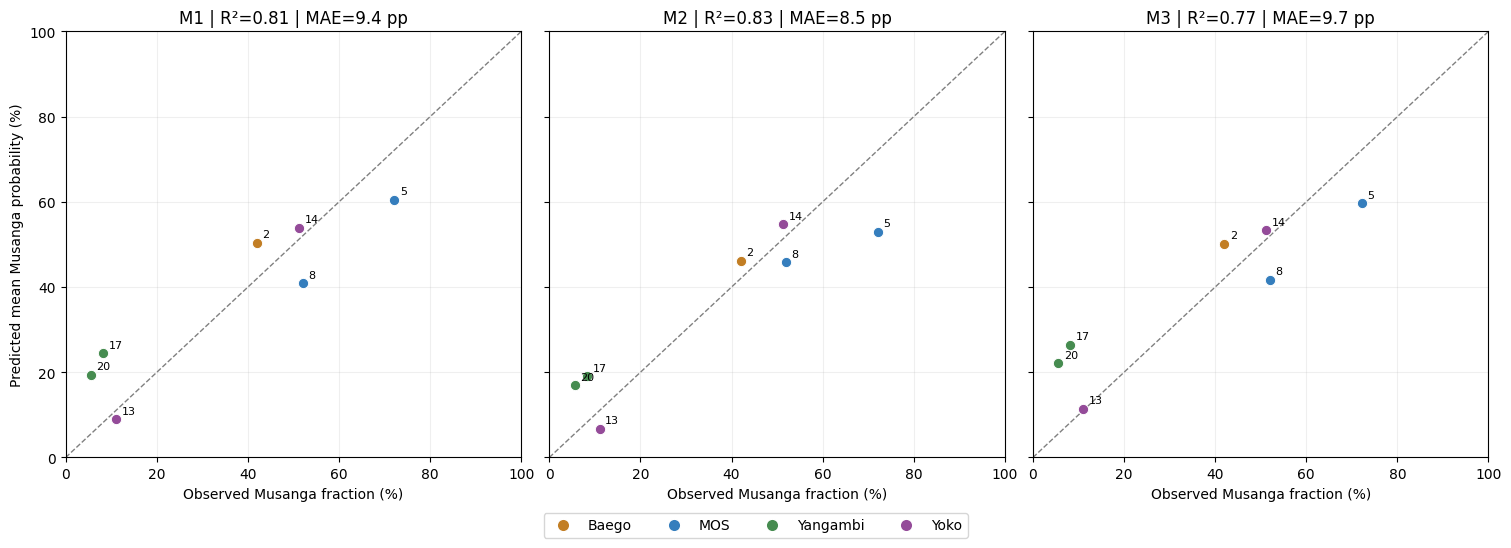

IMPORTANT: these seven holdouts have NOT trained M1/M2 or M3 calibration.


In [11]:
from scipy.stats import linregress
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
H=m2.copy()
assert len(H)==7 and set(H.circle_id.astype(int))==HOLDOUT
y=H.observed_fraction.to_numpy(float)
pred=H.predicted_fraction.to_numpy(float)
reg=linregress(y,pred)
MET=pd.DataFrame([dict(model='M2',n_circles=7,
    r2=float(r2_score(y,pred)),pearson_r=float(reg.rvalue),
    slope_pred_vs_obs=float(reg.slope),intercept_pp=float(reg.intercept),
    MAE_pp=float(mean_absolute_error(y,pred)),
    RMSE_pp=float(np.sqrt(mean_squared_error(y,pred))),
    bias_pp=float(np.mean(pred-y)),brier_mean=float(H.brier.mean()))])
print('=== NADINE34 FAST M2: HISTORICAL SEVEN HOLDOUT CIRCLES ===')
display(MET.round(3))
display(H[['circle_id','site','observed_fraction','predicted_fraction','bias_pp','valid_pixels']]
       .sort_values(['site','circle_id']).round(3))
MET.to_csv(OUT/'02C_fast_M2_holdout_metrics.csv',index=False)
H.to_csv(OUT/'02C_fast_M2_7circle_predictions.csv',index=False)
fig,ax=plt.subplots(figsize=(6.6,6.3),constrained_layout=True)
ax.plot([0,100],[0,100],ls='--',lw=1,color='gray')
colors={'Baego':'#c27e24','MOS':'#357ebd','Yangambi':'#468c50','Yoko':'#944b99'}
for row in H.itertuples(index=False):
    ax.scatter(row.observed_fraction,row.predicted_fraction,color=colors[row.site],
               s=70,edgecolor='white',linewidth=.8,zorder=3)
    ax.annotate(str(row.circle_id),(row.observed_fraction,row.predicted_fraction),
                xytext=(5,5),textcoords='offset points',fontsize=9)
ax.set(xlim=(0,100),ylim=(0,100),xlabel='Observed Musanga canopy fraction (%)',
       ylabel='Mean predicted Musanga probability (%)',
       title=f'Nadine34 M2 | R²={MET.r2.iloc[0]:.3f}, MAE={MET.MAE_pp.iloc[0]:.2f} pp')
ax.grid(alpha=.2)
fig.savefig(OUT/'02C_fast_M2_seven_holdout_scatter.png',dpi=180,bbox_inches='tight')
display(fig);plt.close(fig)
print('Historical 02C M2 benchmark: R² 0.830 | MAE 8.522 pp (old reference; not identical experiment).')


## 10 — Fast M2 experiment contract

Record the frozen seven-circle split, source manifest and mixed-precision setting. This is a targeted consistency check, **not** a substitute for 34-circle three-fold spatial CV in 02D.


In [12]:
contract=dict(schema='musanga_v3_fast_m2_nadine34_legacy7',
    reference_count=34,development_circles=sorted(DEV),holdout_circles=sorted(HOLDOUT),
    data_manifest=str(ROOT/'Outputs/V3/00_input_audit/00_input_manifest.json'),
    candidate_windows=str(REF/'01_candidate_windows.csv'),
    model='M2 TinyUNet native RGB; partial tree crowns plus exhaustive development circles',
    epochs=EPOCHS,batch=BATCH,crop_px=CROP,seed=SEED,
    amp=bool(USE_AMP),precision='CUDA float16 autocast; BCE fp32',
    annotation_conflicts='zero loss weight during training; retained in validation',
    checkpoint=str(OUT/'M2_model.pt'),
    result_csv=str(OUT/'02C_fast_M2_7circle_predictions.csv'),
    metrics_csv=str(OUT/'02C_fast_M2_holdout_metrics.csv'),
    note='M1 and M3 skipped; old 22-circle results preserved; not 34-circle CV')
(OUT/'02C_fast_M2_experiment_contract.json').write_text(json.dumps(contract,indent=2))
print('Saved fast M2 experiment contract and outputs at',OUT,flush=True)


=== DEVELOPMENT / CALIBRATION CIRCLES (not an independent performance estimate) ===


,circles,fraction_MAE_pp,signed_bias_pp
model,,,
M1,15,18.140,-1.903
M2,15,16.686,-2.341
M3,15,18.795,-0.362



=== INDEPENDENT HOLDOUT — model ranking by fraction MAE ===


,model,r2,slope_pred_vs_obs,intercept_pp,MAE_pp,RMSE_pp,bias_pp,brier_mean
1,M2,0.830,0.698,10.474,8.522,10.019,0.007,0.126
0,M1,0.808,0.684,13.230,9.419,10.663,2.279,0.142
2,M3,0.773,0.632,15.952,9.740,11.573,3.201,0.141


Files: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/02_simple
Primary figure: 02C_observed_vs_predicted_holdout.png
